
### EN3160 Assignment 03 — Neural Networks

**Rahman MFA | 230507R**

University of Moratuwa  
EN3160 - Image Processing and Machine Vision


In [1]:
from pathlib import Path
import random
import numpy as np
import torch
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA = Path('data'); DATA.mkdir(exist_ok=True)
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
print('Device:', device, '| torch:', torch.__version__)

Device: cuda | torch: 2.11.0+cu128


#### Q1 — Dense network with manual forward and backward passes

100.0%


Epoch 01/10 | loss 1.8528 | train 39.23% | test 38.87%
Epoch 02/10 | loss 1.7199 | train 41.68% | test 40.92%
Epoch 03/10 | loss 1.6670 | train 43.73% | test 42.73%
Epoch 04/10 | loss 1.6302 | train 44.26% | test 42.97%
Epoch 05/10 | loss 1.5967 | train 46.05% | test 43.43%
Epoch 06/10 | loss 1.5675 | train 46.82% | test 44.43%
Epoch 07/10 | loss 1.5386 | train 48.38% | test 45.77%
Epoch 08/10 | loss 1.5124 | train 49.11% | test 46.17%
Epoch 09/10 | loss 1.4854 | train 50.22% | test 46.24%
Epoch 10/10 | loss 1.4618 | train 51.11% | test 46.98%


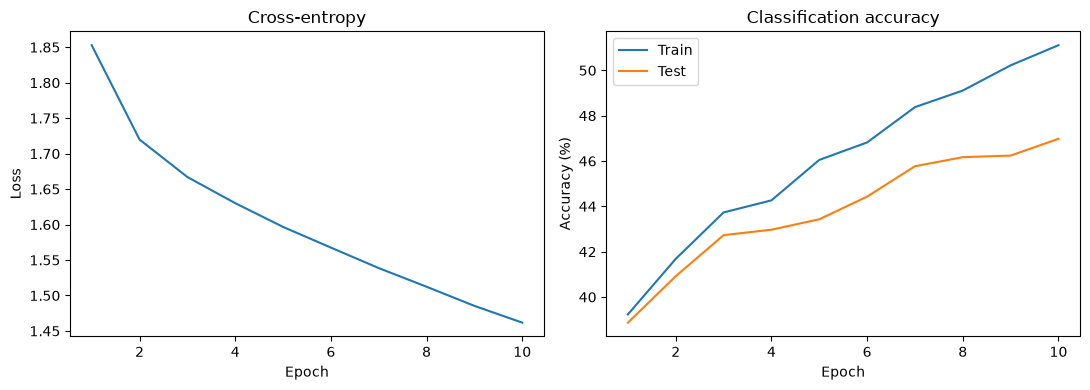

In [2]:
cifar_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.5,)*3, (.5,)*3)])
cifar_train = datasets.CIFAR10(DATA, train=True, download=True, transform=cifar_tf)
cifar_test = datasets.CIFAR10(DATA, train=False, download=True, transform=cifar_tf)
q1_train = DataLoader(cifar_train, batch_size=100, shuffle=True, num_workers=0)
q1_test = DataLoader(cifar_test, batch_size=256, shuffle=False, num_workers=0)
Din, H, K = 3072, 100, 10
w1 = torch.randn(Din, H, device=device) / np.sqrt(Din)
b1 = torch.zeros(H, device=device)
w2 = torch.randn(H, K, device=device) / np.sqrt(H)
b2 = torch.zeros(K, device=device)

def dense_forward(images):
    x = images.flatten(1)
    h = torch.sigmoid(x @ w1 + b1)
    z = h @ w2 + b2
    return x, h, z

@torch.no_grad()
def dense_accuracy(loader):
    correct = total = 0
    for images, targets in loader:
        _, _, z = dense_forward(images.to(device))
        correct += (z.argmax(1) == targets.to(device)).sum().item()
        total += len(targets)
    return 100 * correct / total

q1_history = {'loss':[], 'train_acc':[], 'test_acc':[]}
lr = .1
for epoch in range(10):
    total_loss = total_count = 0
    for images, targets in q1_train:
        targets = targets.to(device)
        x, h, logits = dense_forward(images.to(device))
        n = len(targets)
        probs = torch.softmax(logits, dim=1)
        loss = -torch.log(probs[torch.arange(n, device=device), targets].clamp_min(1e-12)).mean()
        dz = probs.clone()
        dz[torch.arange(n, device=device), targets] -= 1
        dz /= n
        dw2, db2 = h.T @ dz, dz.sum(0)
        dh = (dz @ w2.T) * h * (1-h)
        dw1, db1 = x.T @ dh, dh.sum(0)
        w1 -= lr * dw1; b1 -= lr * db1
        w2 -= lr * dw2; b2 -= lr * db2
        total_loss += loss.item() * n
        total_count += n
    q1_history['loss'].append(total_loss/total_count)
    q1_history['train_acc'].append(dense_accuracy(q1_train))
    q1_history['test_acc'].append(dense_accuracy(q1_test))
    print(f'Epoch {epoch+1:02d}/10 | loss {q1_history["loss"][-1]:.4f} | train {q1_history["train_acc"][-1]:.2f}% | test {q1_history["test_acc"][-1]:.2f}%')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1,11), q1_history['loss']); ax[0].set(title='Cross-entropy', xlabel='Epoch', ylabel='Loss')
ax[1].plot(range(1,11), q1_history['train_acc'], label='Train')
ax[1].plot(range(1,11), q1_history['test_acc'], label='Test')
ax[1].legend(); ax[1].set(title='Classification accuracy', xlabel='Epoch', ylabel='Accuracy (%)')
plt.tight_layout(); plt.savefig(OUT/'q1_curves.png', dpi=150); plt.show()


### Results and Discussion

After 10 epochs, the network achieved a training accuracy of 51.11%
and a test accuracy of 46.98%. The cross-entropy loss decreased from
1.8528 in the first epoch to 1.4618 in the final epoch.

The decrease in loss and the general improvement in accuracy show
that the network learned useful patterns from the CIFAR-10 images.
However, the final test accuracy remained relatively low. One reason
is that the images were flattened into vectors before being passed
to the dense layers. This removes their two-dimensional spatial
arrangement, making it harder for the model to learn image features
such as edges and shapes.

The training accuracy was 4.13 percentage points higher than the
test accuracy. This indicates a performance gap between the training
and test sets, although the difference alone does not establish severe
overfitting. Overall, the experiment demonstrates that a dense network
can perform image classification, but it is less suited to exploiting
spatial information than a convolutional network.


#### Q2 — LeNet-5 vs modern CNN on MNIST

In [3]:
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.1307,), (.3081,))])
mnist_train = datasets.MNIST(DATA, train=True, download=True, transform=mnist_tf)
mnist_test = datasets.MNIST(DATA, train=False, download=True, transform=mnist_tf)
train_mnist = DataLoader(mnist_train, batch_size=128, shuffle=True, num_workers=0)
test_mnist = DataLoader(mnist_test, batch_size=256, shuffle=False, num_workers=0)

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1,6,5,padding=2), nn.Tanh(), nn.AvgPool2d(2),
                                      nn.Conv2d(6,16,5), nn.Tanh(), nn.AvgPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(16*5*5,120), nn.Tanh(),
                                        nn.Linear(120,84), nn.Tanh(), nn.Linear(84,10))
    def forward(self,x): return self.classifier(self.features(x))

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),
                                    nn.Conv2d(32,64,3,padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2),
                                    nn.Conv2d(64,128,3,padding=1),nn.BatchNorm2d(128),nn.ReLU(),
                                    nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.3),nn.Linear(128,10))
    def forward(self,x): return self.layers(x)

def evaluate(model,loader,criterion,collect=False):
    model.eval(); total_loss = correct = total = 0
    true, pred = [], []
    with torch.no_grad():
        for x,y in loader:
            x,y = x.to(device), y.to(device)
            scores = model(x); p = scores.argmax(1)
            total_loss += criterion(scores,y).item()*len(y)
            correct += (p==y).sum().item(); total += len(y)
            if collect: true.extend(y.cpu().tolist()); pred.extend(p.cpu().tolist())
    return (total_loss/total,100*correct/total,true,pred)

def train_supervised(model,train_loader,test_loader,epochs=10,lr=.001):
    model=model.to(device); loss_fn=nn.CrossEntropyLoss()
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    hist={'train_loss':[],'train_acc':[],'test_loss':[],'test_acc':[]}
    for epoch in range(epochs):
        model.train(); count=correct=0; loss_total=0
        for x,y in train_loader:
            x,y=x.to(device),y.to(device)
            opt.zero_grad(set_to_none=True)
            scores=model(x); loss=loss_fn(scores,y)
            loss.backward(); opt.step()
            count+=len(y); correct+=(scores.argmax(1)==y).sum().item(); loss_total+=loss.item()*len(y)
        test_loss,test_acc,_,_=evaluate(model,test_loader,loss_fn)
        for key,val in [('train_loss',loss_total/count),('train_acc',100*correct/count),
                        ('test_loss',test_loss),('test_acc',test_acc)]: hist[key].append(val)
        print(f'{epoch+1:02d}/{epochs} train {hist["train_acc"][-1]:.2f}% | test {test_acc:.2f}%')
    return model,hist

def plot_history(h,title,file):
    t=range(1,len(h['train_acc'])+1)
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    for metric,axis in [('loss',ax[0]),('acc',ax[1])]:
        axis.plot(t,h['train_'+metric],label='Train')
        axis.plot(t,h['test_'+metric],label='Test')
        axis.set(xlabel='Epoch',ylabel='Loss' if metric=='loss' else 'Accuracy (%)'); axis.legend()
    fig.suptitle(title); plt.tight_layout(); plt.savefig(OUT/file,dpi=150); plt.show()

100.0%
100.0%
100.0%
100.0%



Training LeNet5
01/10 train 91.09% | test 96.68%
02/10 train 97.45% | test 97.88%
03/10 train 98.28% | test 98.69%
04/10 train 98.66% | test 98.61%
05/10 train 98.91% | test 98.70%
06/10 train 99.11% | test 98.92%
07/10 train 99.19% | test 98.81%
08/10 train 99.31% | test 98.69%
09/10 train 99.45% | test 98.77%
10/10 train 99.51% | test 98.86%


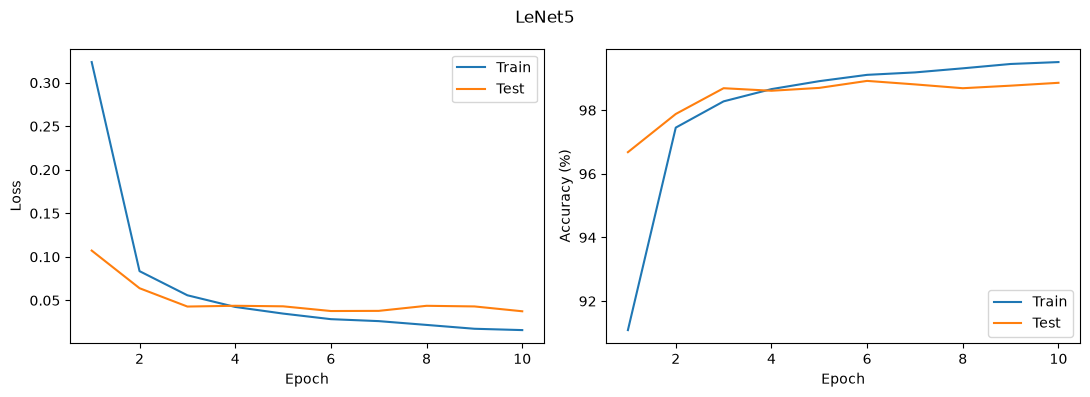

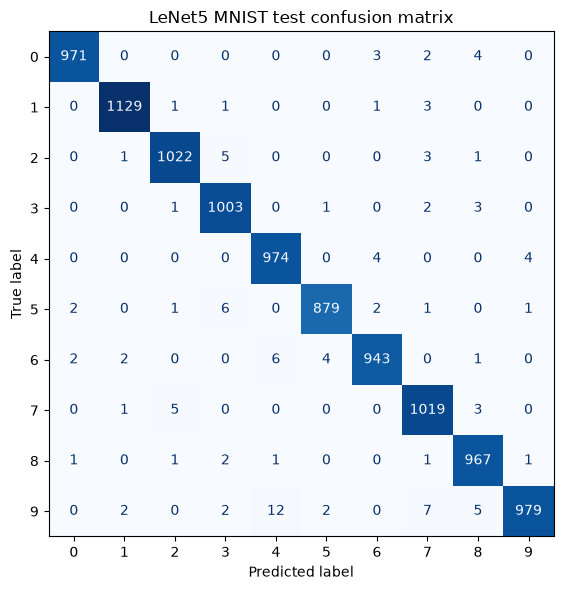

Final test accuracy: 98.86%

Training ModernCNN
01/10 train 89.50% | test 90.43%
02/10 train 96.88% | test 94.24%
03/10 train 97.55% | test 95.28%
04/10 train 97.84% | test 98.03%
05/10 train 98.21% | test 98.22%
06/10 train 98.34% | test 97.59%
07/10 train 98.48% | test 98.48%
08/10 train 98.60% | test 97.65%
09/10 train 98.78% | test 98.37%
10/10 train 98.84% | test 98.08%


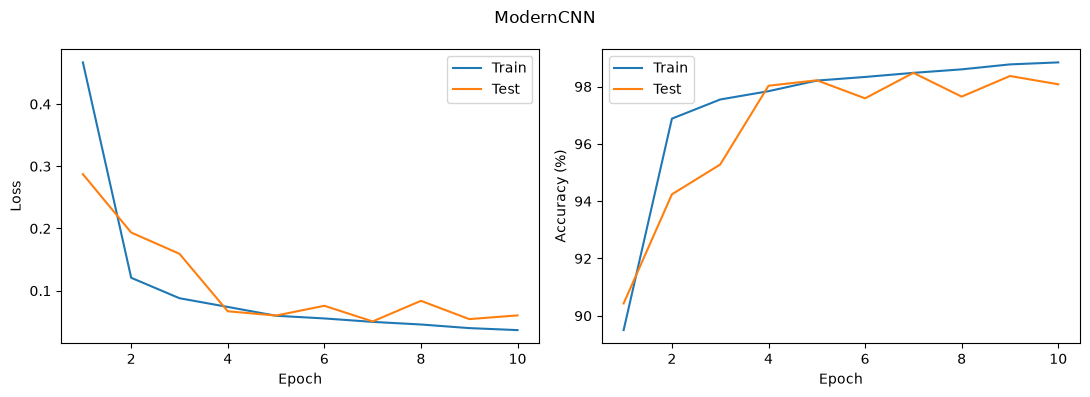

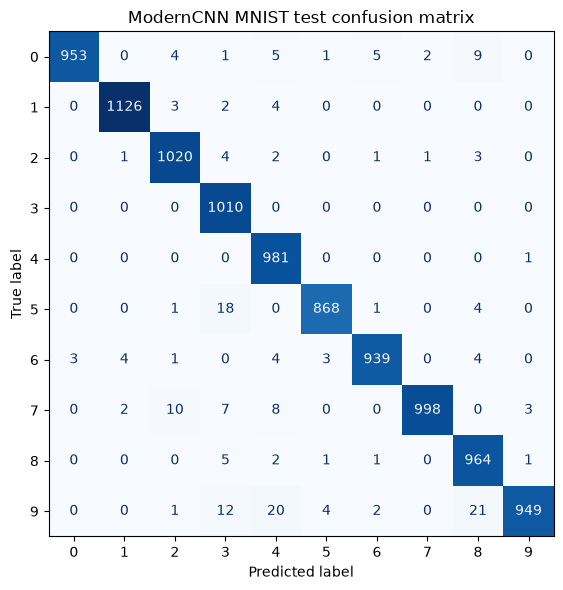

Final test accuracy: 98.08%


In [4]:
q2_results={}
for name,model_type in [('LeNet5',LeNet5),('ModernCNN',SmallCNN)]:
    print('\nTraining',name)
    torch.manual_seed(SEED)
    net,hist=train_supervised(model_type(),train_mnist,test_mnist,epochs=10)
    q2_results[name]=(net,hist)
    plot_history(hist,name,'q2_'+name.lower()+'_curves.png')
    _,acc,truth,pred=evaluate(net,test_mnist,nn.CrossEntropyLoss(),collect=True)
    fig,ax=plt.subplots(figsize=(7,6))
    ConfusionMatrixDisplay(confusion_matrix(truth,pred,labels=list(range(10))),display_labels=list(range(10))).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(name+' MNIST test confusion matrix')
    plt.tight_layout();plt.savefig(OUT/('q2_'+name.lower()+'_confusion.png'),dpi=150);plt.show()
    print('Final test accuracy:',f'{acc:.2f}%')


### Results and Discussion

Both models achieved high accuracy on the MNIST test set after
10 epochs. LeNet-5 achieved 98.86% test accuracy, while the modern
CNN achieved 98.08%. In this experiment, LeNet-5 performed better
by 0.78 percentage points.

The loss curves show that both models learned quickly during the
first few epochs. LeNet-5 reached its final test accuracy with a
relatively small difference between its training and test accuracy.
Its final training accuracy was 99.51%, compared with 98.86% on
the test set.

The modern CNN reached a training accuracy of 98.84% and a test
accuracy of 98.08%. Its test accuracy fluctuated slightly during
training, even though its training accuracy continued to improve.
This suggests that improvements in training performance did not
always produce equivalent improvements on the test set.

The confusion matrices show that most digits were classified
correctly by both models. For the modern CNN, some of the more
noticeable errors involved confusing digit 5 with digit 3 and
digit 9 with digits 4 and 8. LeNet-5 also made errors between
similar-looking digits, including some instances of digit 9 being
classified as digit 4.

Overall, LeNet-5 achieved the higher test accuracy in this run.
However, the difference was small, and these results do not prove
that LeNet-5 is always better than the modern CNN. The outcome
depends on the architectures, training settings and particular
training run used in this experiment.


#### Q3 — ResNet18 transfer learning on Hymenoptera

In [6]:

import urllib.request
import zipfile
from pathlib import Path

# Keep the dataset in a short Windows path to avoid extraction errors.
HYM_DATA = Path(r"C:\uomdata")
HYM_DATA.mkdir(parents=True, exist_ok=True)

hym_root = HYM_DATA / "hymenoptera_data"
archive = HYM_DATA / "hymenoptera_data.zip"

# Download the dataset if it is not already available.
if not (hym_root / "train").exists() or not (hym_root / "val").exists():
    if not archive.exists():
        print("Downloading Hymenoptera dataset...")
        urllib.request.urlretrieve(
            "https://download.pytorch.org/tutorial/hymenoptera_data.zip",
            archive
        )

    print("Extracting dataset...")
    with zipfile.ZipFile(archive, "r") as z:
        z.extractall(HYM_DATA)

assert (hym_root / "train").exists(), "Training dataset not found"
assert (hym_root / "val").exists(), "Validation dataset not found"

# ImageNet normalization for pretrained ResNet18.
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    normalize
])

val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    normalize
])

hym_train = datasets.ImageFolder(
    hym_root / "train",
    transform=train_tf
)

hym_val = datasets.ImageFolder(
    hym_root / "val",
    transform=val_tf
)

assert hym_train.classes == hym_val.classes

train_hym = DataLoader(
    hym_train, batch_size=16, shuffle=True, num_workers=0
)

val_hym = DataLoader(
    hym_val, batch_size=32, shuffle=False, num_workers=0
)

print("Classes:", hym_train.classes)
print("Training images:", len(hym_train))
print("Validation images:", len(hym_val))
print("Dataset loaded successfully.")

def make_resnet(frozen):
    model=models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if frozen:
        for param in model.parameters(): param.requires_grad=False
    model.fc=nn.Linear(model.fc.in_features,2)
    return model

def train_resnet(model,frozen,epochs=10):
    model=model.to(device)
    loss_fn=nn.CrossEntropyLoss()
    optimizer=torch.optim.SGD((p for p in model.parameters() if p.requires_grad),lr=.001,momentum=.9)
    history={'train_loss':[],'train_acc':[],'test_loss':[],'test_acc':[]}
    for epoch in range(epochs):
        model.train()
        if frozen:
            # Prevent updates to frozen batch-normalization running statistics.
            model.eval();model.fc.train()
        total=correct=0;loss_sum=0
        for x,y in train_hym:
            x,y=x.to(device),y.to(device)
            optimizer.zero_grad(set_to_none=True)
            z=model(x);loss=loss_fn(z,y)
            loss.backward();optimizer.step()
            total+=len(y);correct+=(z.argmax(1)==y).sum().item();loss_sum+=loss.item()*len(y)
        val_loss,val_acc,_,_=evaluate(model,val_hym,loss_fn)
        for key,value in [('train_loss',loss_sum/total),('train_acc',100*correct/total),
                          ('test_loss',val_loss),('test_acc',val_acc)]: history[key].append(value)
        print(f'{epoch+1:02d}/{epochs}: train {100*correct/total:.2f}% val {val_acc:.2f}%')
    return model,history

Extracting dataset...
Classes: ['ants', 'bees']
Training images: 244
Validation images: 153
Dataset loaded successfully.



Finetuning
01/10: train 75.41% val 93.46%
02/10: train 84.43% val 91.50%
03/10: train 88.93% val 94.77%
04/10: train 92.62% val 92.81%
05/10: train 94.26% val 93.46%
06/10: train 95.49% val 94.12%
07/10: train 88.11% val 94.12%
08/10: train 96.72% val 92.16%
09/10: train 93.44% val 93.46%
10/10: train 94.26% val 94.77%


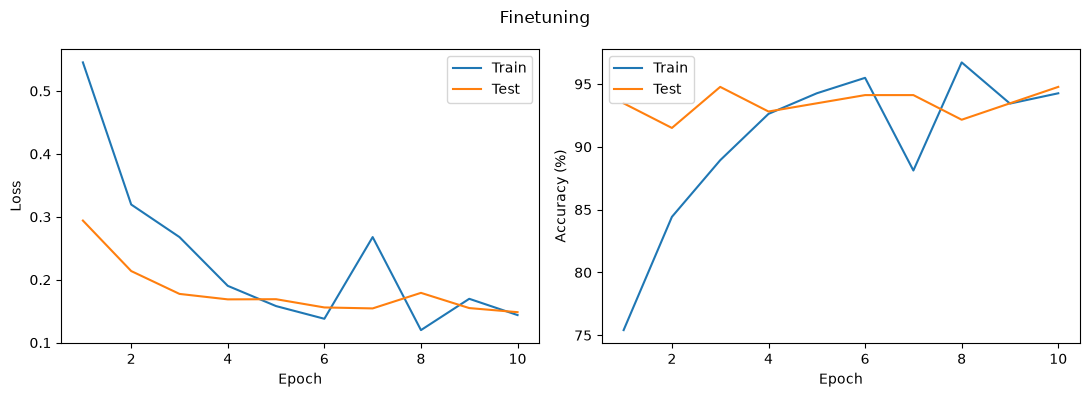

Finetuning: train 94.26%, validation 94.77%

FeatureExtraction
01/10: train 77.87% val 96.08%
02/10: train 92.62% val 94.77%
03/10: train 93.85% val 96.08%
04/10: train 95.49% val 96.08%
05/10: train 97.13% val 94.77%
06/10: train 95.08% val 95.42%
07/10: train 95.49% val 96.08%
08/10: train 96.72% val 94.77%
09/10: train 96.72% val 96.08%
10/10: train 95.08% val 95.42%


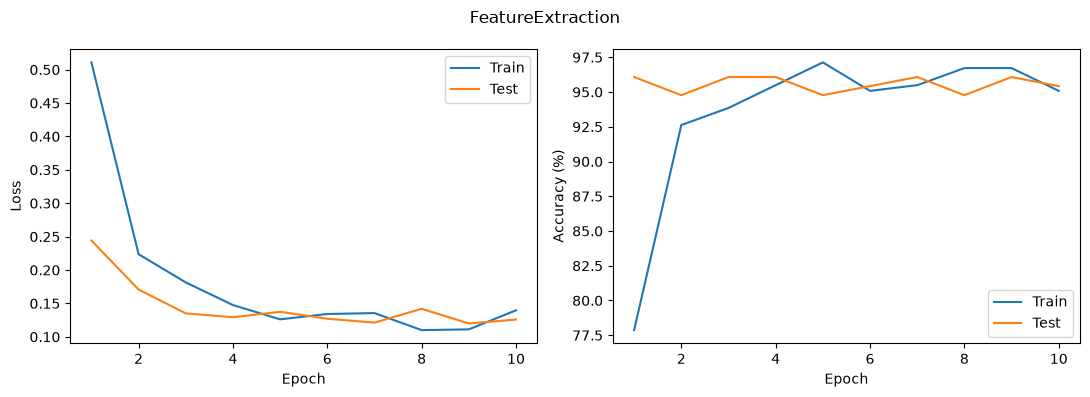

FeatureExtraction: train 95.08%, validation 95.42%


In [7]:
q3_results={}
for title,frozen in [('Finetuning',False),('FeatureExtraction',True)]:
    print('\n'+title)
    torch.manual_seed(SEED)
    model,hist=train_resnet(make_resnet(frozen),frozen,epochs=10)
    q3_results[title]=(model,hist)
    plot_history(hist,title,'q3_'+title.lower()+'_curves.png')
    print(f'{title}: train {hist["train_acc"][-1]:.2f}%, validation {hist["test_acc"][-1]:.2f}%')


## Q3 — Results and Discussion

The pretrained ResNet18 was evaluated using two approaches:
fine-tuning the network and using it as a feature extractor.
Both approaches were trained for 10 epochs on the Hymenoptera
dataset, which contains images of ants and bees.

With fine-tuning, the final training accuracy was 94.26% and
the validation accuracy was 94.77%. When the pretrained
convolutional layers were frozen and only the final classification
layer was trained, the final training accuracy was 95.08% and
the validation accuracy was 95.42%.

The feature-extraction approach achieved a slightly higher
validation accuracy in this run. It also requires updating fewer
parameters because the pretrained backbone remains frozen.
The pretrained features therefore provided a useful starting
point for this relatively small dataset.

The validation accuracy changed across epochs for both approaches.
The best validation accuracy observed during training was 94.77%
for fine-tuning and 96.08% for feature extraction. These values
are the highest observed validation accuracies, whereas the final
epoch values reported above describe the models at the end of
training.

The dataset is relatively small, so the results should be
interpreted with care. The validation set was used to monitor
performance, and it is not an independent test set. A separate
test dataset or repeated experiments would be needed to establish
how consistently one approach outperforms the other.

## Overall Comparison

| Experiment | Model | Dataset | Training accuracy | Evaluation accuracy |
|---|---|---|---:|---:|
| Q1 | Dense network | CIFAR-10 | 51.11% | 46.98% |
| Q2 | LeNet-5 | MNIST | 99.51% | 98.86% |
| Q2 | Modern CNN | MNIST | 98.84% | 98.08% |
| Q3 | ResNet18 fine-tuning | Hymenoptera | 94.26% | 94.77% |
| Q3 | ResNet18 feature extraction | Hymenoptera | 95.08% | 95.42% |

For Q1 and Q2, the evaluation accuracy is the test accuracy.
For Q3, it is the validation accuracy.

## Conclusion

The experiments demonstrated how different neural network
architectures can be applied to image classification. The dense
network learned to classify CIFAR-10 images, although its accuracy
was much lower than that of the CNNs on MNIST. Both CNNs performed
well on handwritten digit recognition, with LeNet-5 achieving the
higher test accuracy in this run.

The transfer-learning experiment showed that a pretrained ResNet18
could classify ants and bees with high validation accuracy.
Feature extraction achieved a slightly higher final validation
accuracy than fine-tuning in this run, while requiring fewer
trainable parameters. These results highlight the usefulness of
convolutional features and pretrained networks, particularly when
the available dataset is small.

The results apply to the specific configurations and training runs
used in this assignment. They should not be interpreted as proof
that one architecture is always superior to another.
